<sub>**The Annotated ML Handbook** · Part IV: Visualization · by Mahir Absar Khan</sub>

# Chapter 14: Matplotlib and Seaborn: from first plot to publication figure

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Mahir-606/annotated-ml-handbook/blob/main/notebooks/part-4-visualization/14-viz-matplotlib.ipynb) &nbsp; [📚 Contents](../../book/README.md) &nbsp; [🌐 Web edition](https://mahir-606.github.io/annotated-ml-handbook/)

*Run the setup cell first, then read and run the cells from top to bottom. Every code cell is followed by a table explaining what each line does.*

In [1]:
# Repository setup (not part of the book's examples): run this cell first.
import os, sys
from pathlib import Path

# Files the examples create (CSV, models, figures) go into ./outputs next to the notebook.
OUT = Path.cwd() if Path.cwd().name == "outputs" else Path.cwd() / "outputs"
OUT.mkdir(exist_ok=True)
os.chdir(OUT)

# insurance.csv is the practice dataset created in Chapter 11 and reused by later chapters.
# If it is not here yet, copy it from the repository's data/ folder (or download it in Colab).
if not Path("insurance.csv").exists():
    import shutil, urllib.request
    for base in OUT.parents:
        if (base / "data" / "insurance.csv").exists():
            shutil.copy(base / "data" / "insurance.csv", "insurance.csv")
            break
    else:
        try:
            urllib.request.urlretrieve("https://raw.githubusercontent.com/Mahir-606/"
                                       "annotated-ml-handbook/main/data/insurance.csv", "insurance.csv")
        except Exception as e:
            print("Could not fetch insurance.csv; run Chapter 11 first.", e)

# The figure style used in the book.
import matplotlib.pyplot as plt
from cycler import cycler
plt.rcParams.update({
    "figure.figsize": (7.2, 4.0), "figure.dpi": 100,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.alpha": 0.28, "grid.linewidth": 0.6,
    "axes.prop_cycle": cycler(color=["#1f4fff", "#e0245e", "#0f9b62", "#ff6a00",
                                     "#7b3ff2", "#0091b3", "#d99a00", "#d42a2a"]),
    "axes.titleweight": "bold", "axes.titlesize": 12.5, "axes.titlelocation": "left",
    "font.size": 10.5, "legend.frameon": False, "image.cmap": "viridis",
})

# Plotly: interactive in Jupyter/Colab; tools/run_all.py stores static PNGs so GitHub can show them.
try:
    import plotly.io as pio
    pio.renderers.default = os.environ.get("PLOTLY_RENDERER") or (
        "colab" if "google.colab" in sys.modules else "notebook_connected")
except ImportError:
    pass

# Matplotlib and Seaborn: from first plot to publication figure

A good figure shows in seconds what a table hides. This chapter teaches Matplotlib's object model (the source of most plotting confusion), the essential chart types, Seaborn's statistical plots, and how to export figures that meet journal requirements.

> **📝 Note** · **About the colours in this book**
>
> Figures here use a light house style (no top/right spines, a soft grid, the book's palette). Your default Matplotlib output will look slightly different but contain the same information. Section 14.6 shows how to set a style of your own.

## 14.1 The anatomy of a figure · *Beginner*

> **📖 Definitions**
>
> **Figure**: the whole drawing canvas in Matplotlib, which can contain one or more plots.
>
> **Axes**: one individual plot inside a figure, with its own x-axis, y-axis, title and data. Most plotting methods are called on an Axes.
>
> **Legend**: the key that tells readers which colour or marker belongs to which series.
>
> **Colormap**: a mapping from numbers to colours. **Sequential** maps (viridis) go from low to high; **diverging** maps (RdBu) emphasise departures from a centre value.


A **Figure** is the whole canvas. It contains one or more **Axes**: individual plots, each with its own x-axis, y-axis, title and data. Almost every method you call lives on an Axes.

**The object-oriented interface (recommended)**

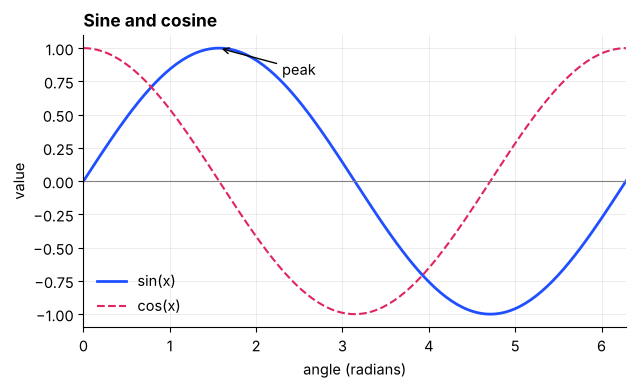

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

x = np.linspace(0, 2 * np.pi, 200)
fig, ax = plt.subplots(figsize=(7, 3.8))
ax.plot(x, np.sin(x), label="sin(x)", lw=2)
ax.plot(x, np.cos(x), label="cos(x)", ls="--")
ax.axhline(0, color="grey", lw=0.8)
ax.set_title("Sine and cosine")
ax.set_xlabel("angle (radians)")
ax.set_ylabel("value")
ax.set_xlim(0, 2 * np.pi)
ax.legend(loc="lower left")
ax.annotate("peak", xy=(np.pi / 2, 1), xytext=(2.3, 0.8),
            arrowprops=dict(arrowstyle="->"))
plt.show()

<details open><summary><b>What each line does</b></summary>

<table>
<tr><td><code>import numpy as np</code></td><td>Import NumPy (the array library) under the short name <code>np</code>.</td></tr>
<tr><td><code>import pandas as pd</code></td><td>Import pandas (the table library) under the short name <code>pd</code>.</td></tr>
<tr><td><code>import matplotlib.pyplot as plt</code></td><td>pyplot: the plotting interface, conventionally imported as plt.</td></tr>
<tr><td><code>x = np.linspace(0, 2 * np.pi, 200)</code></td><td>200 points from 0 to 2π for smooth curves.</td></tr>
<tr><td><code>fig, ax = plt.subplots(figsize=(7, 3.8))</code></td><td>Create a Figure and one Axes. figsize is in inches (width, height).</td></tr>
<tr><td><code>ax.plot(x, np.sin(x), label=&quot;sin(x)&quot;, lw=2)</code></td><td>A line plot. <code>lw</code> = line width. <code>label</code> is used by the legend.</td></tr>
<tr><td><code>ax.plot(x, np.cos(x), label=&quot;cos(x)&quot;, ls=&quot;--&quot;)</code></td><td><code>ls</code> = line style: &quot;-&quot;, &quot;--&quot;, &quot;:&quot;, &quot;-.&quot;.</td></tr>
<tr><td><code>ax.axhline(0, color=&quot;grey&quot;, lw=0.8)</code></td><td>A horizontal reference line across the whole axes.</td></tr>
<tr><td><code>ax.set_title(&quot;Sine and cosine&quot;)</code></td><td>Axes title.</td></tr>
<tr><td><code>ax.set_xlabel(&quot;angle (radians)&quot;)</code></td><td>Always label axes, with units.</td></tr>
<tr><td><code>ax.set_ylabel(&quot;value&quot;)</code></td><td>Label the y-axis.</td></tr>
<tr><td><code>ax.set_xlim(0, 2 * np.pi)</code></td><td>Control the visible range.</td></tr>
<tr><td><code>ax.legend(loc=&quot;lower left&quot;)</code></td><td>Show the labels; <code>loc</code> chooses the corner.</td></tr>
<tr><td><code>ax.annotate(&quot;peak&quot;, xy=(np.pi / 2, 1), xytext=(2.3, 0.8),</code></td><td>Text &quot;peak&quot; placed at (2.3, 0.8), pointing to the maximum at (π/2, 1)...</td></tr>
<tr><td><code>&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;arrowprops=dict(arrowstyle=&quot;-&gt;&quot;))</code></td><td>Point an arrow at a data coordinate.</td></tr>
<tr><td><code>plt.show()</code></td><td>Render the figure (in scripts this opens a window).</td></tr>
</table>
</details>

> **💡 Tip** · **`plt.plot()` vs `ax.plot()`**
>
> Tutorials often call `plt.plot(...)`, `plt.title(...)`: the *pyplot state machine*, which acts on "the current axes". It is fine for quick one-off plots. As soon as you have more than one panel, use `fig, ax = plt.subplots()` and call methods on `ax`; the setter names are `ax.set_title`, `ax.set_xlabel`, and so on.

## 14.2 The essential chart types · *Beginner*

**Six workhorse plots in a grid**

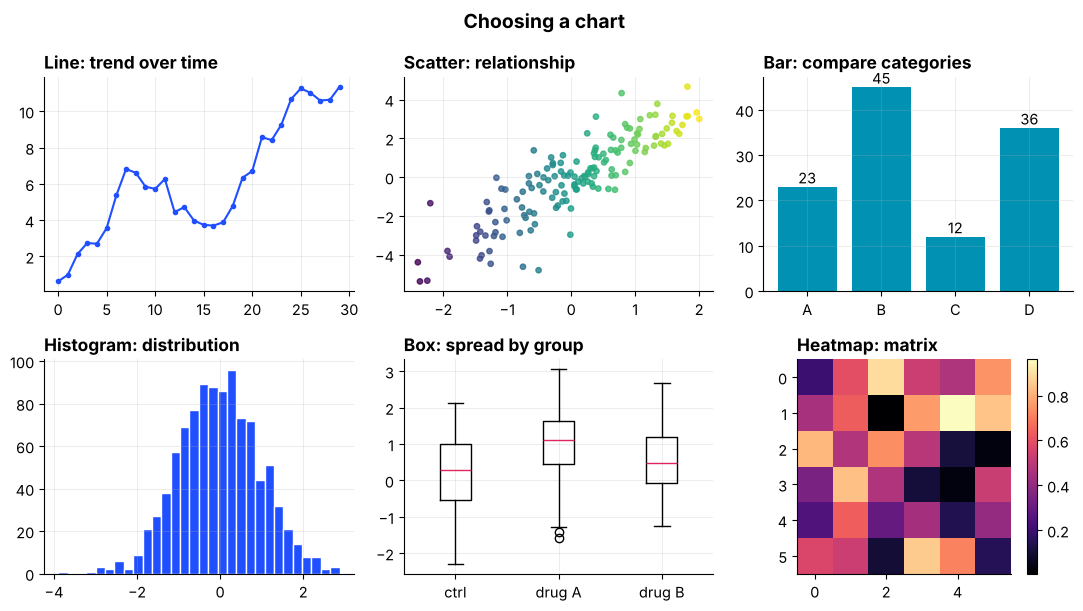

In [3]:
rng = np.random.default_rng(0)
fig, axes = plt.subplots(2, 3, figsize=(11, 6.2))

t = np.arange(30)
axes[0, 0].plot(t, np.cumsum(rng.normal(0.5, 1, 30)), marker="o", ms=3)
axes[0, 0].set_title("Line: trend over time")

a = rng.normal(size=150)
axes[0, 1].scatter(a, 2 * a + rng.normal(size=150), c=a, cmap="viridis", s=15, alpha=0.8)
axes[0, 1].set_title("Scatter: relationship")

cats, vals = ["A", "B", "C", "D"], [23, 45, 12, 36]
bars = axes[0, 2].bar(cats, vals, color="#0091b3")
axes[0, 2].bar_label(bars)
axes[0, 2].set_title("Bar: compare categories")

axes[1, 0].hist(rng.normal(0, 1, 1000), bins=30, edgecolor="white")
axes[1, 0].set_title("Histogram: distribution")

groups = [rng.normal(m, 1, 80) for m in (0, 1, 0.5)]
axes[1, 1].boxplot(groups, tick_labels=["ctrl", "drug A", "drug B"])
axes[1, 1].set_title("Box: spread by group")

im = axes[1, 2].imshow(rng.random((6, 6)), cmap="magma")
fig.colorbar(im, ax=axes[1, 2])
axes[1, 2].set_title("Heatmap: matrix")
axes[1, 2].grid(False)

fig.suptitle("Choosing a chart", fontsize=14, fontweight="bold")
fig.tight_layout()
plt.show()

<details open><summary><b>What each line does</b></summary>

<table>
<tr><td><code>rng = np.random.default_rng(0)</code></td><td>Seeded generator for the example data.</td></tr>
<tr><td><code>fig, axes = plt.subplots(2, 3, figsize=(11, 6.2))</code></td><td>A 2x3 grid; <code>axes</code> is a 2-D array of Axes objects.</td></tr>
<tr><td><code>t = np.arange(30)</code></td><td>30 time steps.</td></tr>
<tr><td><code>axes[0, 0].plot(t, np.cumsum(rng.normal(0.5, 1, 30)), marker=&quot;o&quot;, ms=3)</code></td><td>LINE: change over an ordered variable. ms = marker size.</td></tr>
<tr><td><code>axes[0, 0].set_title(&quot;Line: trend over time&quot;)</code></td><td>Panel title (row 0, column 0).</td></tr>
<tr><td><code>a = rng.normal(size=150)</code></td><td>150 random x values.</td></tr>
<tr><td><code>axes[0, 1].scatter(a, 2 * a + rng.normal(size=150), c=a, cmap=&quot;viridis&quot;, s=15, alpha=0.8)</code></td><td>SCATTER: two numeric variables; colour encodes a third.</td></tr>
<tr><td><code>axes[0, 1].set_title(&quot;Scatter: relationship&quot;)</code></td><td>Panel title.</td></tr>
<tr><td><code>cats, vals = [&quot;A&quot;, &quot;B&quot;, &quot;C&quot;, &quot;D&quot;], [23, 45, 12, 36]</code></td><td>Category names and their values.</td></tr>
<tr><td><code>bars = axes[0, 2].bar(cats, vals, color=&quot;#0091b3&quot;)</code></td><td>BAR: compare a quantity across categories. Bars must start at zero.</td></tr>
<tr><td><code>axes[0, 2].bar_label(bars)</code></td><td>Write each bar&#x27;s value on top.</td></tr>
<tr><td><code>axes[0, 2].set_title(&quot;Bar: compare categories&quot;)</code></td><td>Panel title.</td></tr>
<tr><td><code>axes[1, 0].hist(rng.normal(0, 1, 1000), bins=30, edgecolor=&quot;white&quot;)</code></td><td>HISTOGRAM: the distribution of one variable. Try several bin counts.</td></tr>
<tr><td><code>axes[1, 0].set_title(&quot;Histogram: distribution&quot;)</code></td><td>Panel title.</td></tr>
<tr><td><code>groups = [rng.normal(m, 1, 80) for m in (0, 1, 0.5)]</code></td><td>Three groups of 80 values with different means.</td></tr>
<tr><td><code>axes[1, 1].boxplot(groups, tick_labels=[&quot;ctrl&quot;, &quot;drug A&quot;, &quot;drug B&quot;])</code></td><td>BOX: median, quartiles, whiskers (1.5 IQR) and outliers per group.</td></tr>
<tr><td><code>axes[1, 1].set_title(&quot;Box: spread by group&quot;)</code></td><td>Panel title.</td></tr>
<tr><td><code>im = axes[1, 2].imshow(rng.random((6, 6)), cmap=&quot;magma&quot;)</code></td><td>HEATMAP: values of a matrix as colours.</td></tr>
<tr><td><code>fig.colorbar(im, ax=axes[1, 2])</code></td><td>A colour bar is required to read a heatmap.</td></tr>
<tr><td><code>axes[1, 2].set_title(&quot;Heatmap: matrix&quot;)</code></td><td>Panel title.</td></tr>
<tr><td><code>axes[1, 2].grid(False)</code></td><td>Grid lines would cut across the heatmap cells.</td></tr>
<tr><td><code>fig.suptitle(&quot;Choosing a chart&quot;, fontsize=14, fontweight=&quot;bold&quot;)</code></td><td>A title for the whole figure.</td></tr>
<tr><td><code>fig.tight_layout()</code></td><td>Adjust spacing so titles and labels don&#x27;t overlap.</td></tr>
<tr><td><code>plt.show()</code></td><td>Draw the figure (in a script this opens a window; in Jupyter it appears below the cell).</td></tr>
</table>
</details>

### 14.2.1 Which chart for which question?

| Question | Chart | Matplotlib | Seaborn |
|---|---|---|---|
| How is one variable distributed? | histogram, KDE, box, violin | `ax.hist` | `sns.histplot`, `sns.kdeplot`, `sns.violinplot` |
| How do two numeric variables relate? | scatter (+ trend line) | `ax.scatter` | `sns.scatterplot`, `sns.regplot` |
| How does a value change over time? | line | `ax.plot` | `sns.lineplot` |
| How do groups compare? | bar (counts/means), box, strip | `ax.bar`, `ax.boxplot` | `sns.barplot`, `sns.boxplot`, `sns.stripplot` |
| How do many variables correlate? | correlation heatmap, pair plot | `ax.imshow` | `sns.heatmap`, `sns.pairplot` |
| How good is my model? | confusion matrix, ROC, residuals, learning curve | scikit-learn `*Display` classes | — |

> **⚠️ Pitfall** · **Chart crimes to avoid**
>
> Truncated y-axes on bar charts; pie charts with many slices; 3-D effects; rainbow ("jet") colour maps for ordered values (use `viridis`, `cividis`, `magma`); red/green as the only distinction (about 8% of men are red-green colour-blind); and unlabelled axes.

## 14.3 Subplots, shared axes and layouts · *Intermediate*

**Shared axes and uneven layouts**

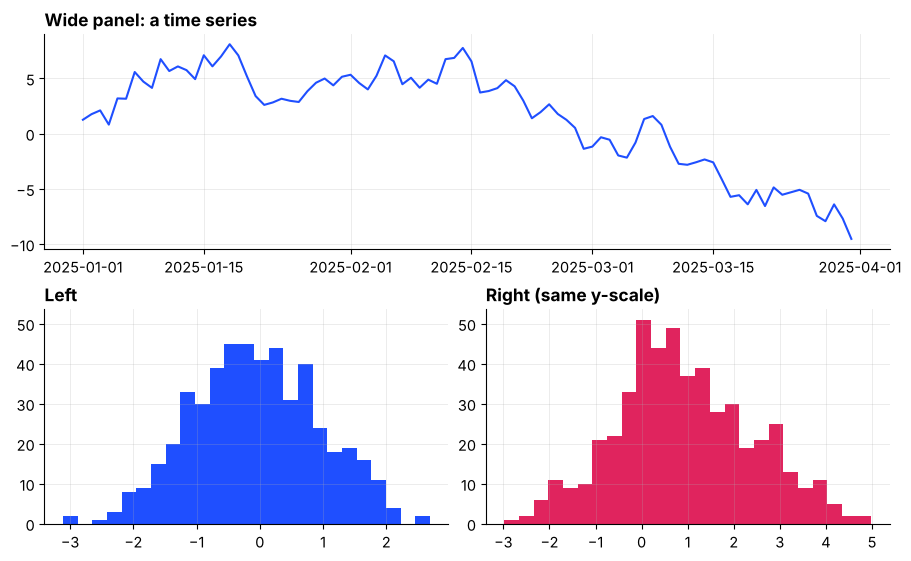

In [4]:
fig, axd = plt.subplot_mosaic([["top", "top"], ["left", "right"]],
                              figsize=(9, 5.5), layout="constrained")
days = pd.date_range("2025-01-01", periods=90)
axd["top"].plot(days, np.cumsum(rng.normal(size=90)))
axd["top"].set_title("Wide panel: a time series")
axd["left"].hist(rng.normal(size=500), bins=25)
axd["left"].set_title("Left")
axd["right"].hist(rng.normal(1, 1.5, 500), bins=25, color="#e0245e")
axd["right"].sharey(axd["left"])
axd["right"].set_title("Right (same y-scale)")
plt.show()

<details open><summary><b>What each line does</b></summary>

<table>
<tr><td><code>fig, axd = plt.subplot_mosaic([[&quot;top&quot;, &quot;top&quot;], [&quot;left&quot;, &quot;right&quot;]],</code></td><td>Name each panel; repeating a name spans cells.</td></tr>
<tr><td><code>&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;figsize=(9, 5.5), layout=&quot;constrained&quot;)</code></td><td>&quot;constrained&quot; layout avoids overlapping labels automatically.</td></tr>
<tr><td><code>days = pd.date_range(&quot;2025-01-01&quot;, periods=90)</code></td><td>90 consecutive dates for the x-axis.</td></tr>
<tr><td><code>axd[&quot;top&quot;].plot(days, np.cumsum(rng.normal(size=90)))</code></td><td>A random walk over time in the wide panel.</td></tr>
<tr><td><code>axd[&quot;top&quot;].set_title(&quot;Wide panel: a time series&quot;)</code></td><td>Title.</td></tr>
<tr><td><code>axd[&quot;left&quot;].hist(rng.normal(size=500), bins=25)</code></td><td>Histogram in the lower-left panel.</td></tr>
<tr><td><code>axd[&quot;left&quot;].set_title(&quot;Left&quot;)</code></td><td>Title.</td></tr>
<tr><td><code>axd[&quot;right&quot;].hist(rng.normal(1, 1.5, 500), bins=25, color=&quot;#e0245e&quot;)</code></td><td>A wider distribution in the lower-right panel.</td></tr>
<tr><td><code>axd[&quot;right&quot;].sharey(axd[&quot;left&quot;])</code></td><td>Share the y-axis with the left panel for fair comparison.</td></tr>
<tr><td><code>axd[&quot;right&quot;].set_title(&quot;Right (same y-scale)&quot;)</code></td><td>Title.</td></tr>
<tr><td><code>plt.show()</code></td><td>Draw the figure (in a script this opens a window; in Jupyter it appears below the cell).</td></tr>
</table>
</details>

## 14.4 Seaborn: statistical plots in one line · *Beginner*

Seaborn sits on top of Matplotlib, works directly with DataFrames, and handles grouping, colour and statistics for you.

**Distribution and relationship by group**

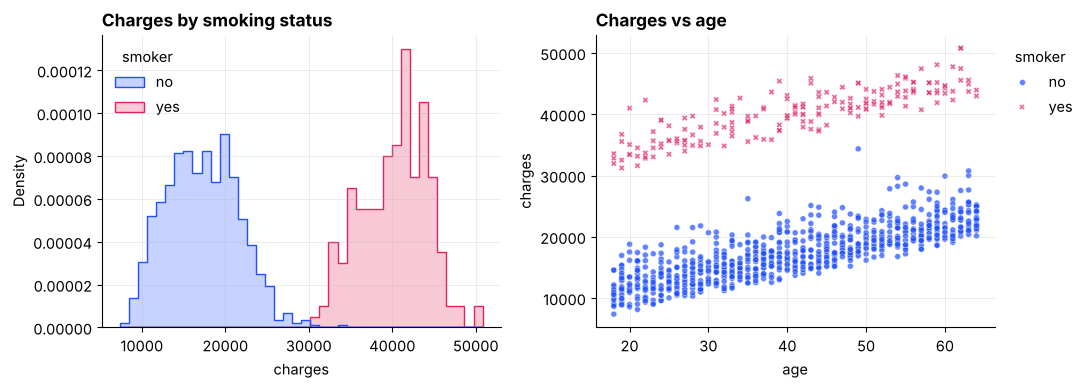

In [5]:
import seaborn as sns

ins = pd.read_csv("insurance.csv")
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
sns.histplot(data=ins, x="charges", hue="smoker", bins=40,
             element="step", stat="density", common_norm=False, ax=axes[0])
axes[0].set_title("Charges by smoking status")
sns.scatterplot(data=ins, x="age", y="charges", hue="smoker",
                style="smoker", s=18, alpha=0.7, ax=axes[1])
axes[1].set_title("Charges vs age")
sns.move_legend(axes[1], "upper left", bbox_to_anchor=(1, 1))
plt.tight_layout()
plt.show()

<details open><summary><b>What each line does</b></summary>

<table>
<tr><td><code>import seaborn as sns</code></td><td>Import Seaborn (statistical plots built on Matplotlib) under the short name <code>sns</code>.</td></tr>
<tr><td><code>ins = pd.read_csv(&quot;insurance.csv&quot;)</code></td><td>The practice dataset from Part III.</td></tr>
<tr><td><code>fig, axes = plt.subplots(1, 2, figsize=(11, 4))</code></td><td>One row, two panels.</td></tr>
<tr><td><code>sns.histplot(data=ins, x=&quot;charges&quot;, hue=&quot;smoker&quot;, bins=40,</code></td><td>Histogram of charges, one colour per smoker group...</td></tr>
<tr><td><code>&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;element=&quot;step&quot;, stat=&quot;density&quot;, common_norm=False, ax=axes[0])</code></td><td>Density per group so groups of different size compare fairly.</td></tr>
<tr><td><code>axes[0].set_title(&quot;Charges by smoking status&quot;)</code></td><td>Title.</td></tr>
<tr><td><code>sns.scatterplot(data=ins, x=&quot;age&quot;, y=&quot;charges&quot;, hue=&quot;smoker&quot;,</code></td><td>Age vs charges, coloured by smoker...</td></tr>
<tr><td><code>&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;style=&quot;smoker&quot;, s=18, alpha=0.7, ax=axes[1])</code></td><td><code>hue</code> -&gt; colour, <code>style</code> -&gt; marker shape (redundant encoding helps colour-blind readers).</td></tr>
<tr><td><code>axes[1].set_title(&quot;Charges vs age&quot;)</code></td><td>Title.</td></tr>
<tr><td><code>sns.move_legend(axes[1], &quot;upper left&quot;, bbox_to_anchor=(1, 1))</code></td><td>Move the legend outside the plot so it hides no points.</td></tr>
<tr><td><code>plt.tight_layout()</code></td><td>Adjust spacing so titles and labels don&#x27;t overlap.</td></tr>
<tr><td><code>plt.show()</code></td><td>Draw the figure (in a script this opens a window; in Jupyter it appears below the cell).</td></tr>
</table>
</details>

**Comparing groups**

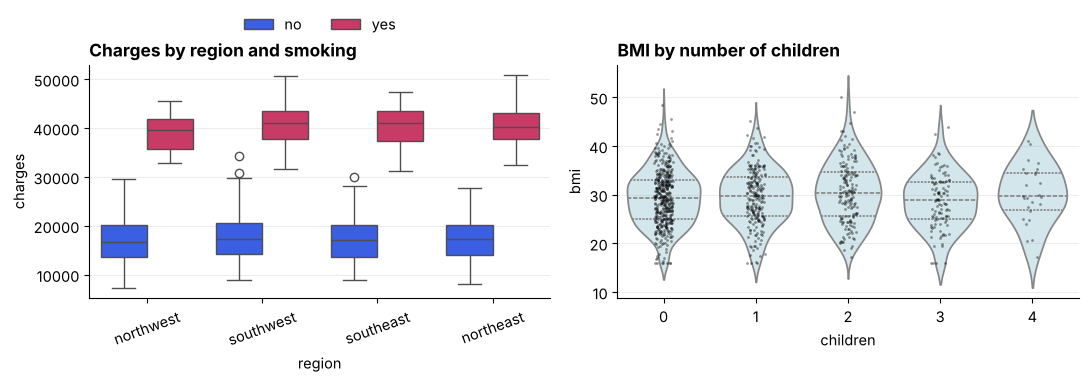

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
sns.boxplot(data=ins, x="region", y="charges", hue="smoker", ax=axes[0])
axes[0].set_title("Charges by region and smoking")
axes[0].tick_params(axis="x", rotation=20)
sns.move_legend(axes[0], "lower center", bbox_to_anchor=(0.5, 1.08), ncol=2, title=None)
sns.violinplot(data=ins, x="children", y="bmi", inner="quart", color="#cfe8f0", ax=axes[1])
sns.stripplot(data=ins, x="children", y="bmi", size=2, alpha=0.4, color="k", ax=axes[1])
axes[1].set_title("BMI by number of children")
plt.tight_layout()
plt.show()

<details open><summary><b>What each line does</b></summary>

<table>
<tr><td><code>fig, axes = plt.subplots(1, 2, figsize=(11, 4))</code></td><td>One row, two panels.</td></tr>
<tr><td><code>sns.boxplot(data=ins, x=&quot;region&quot;, y=&quot;charges&quot;, hue=&quot;smoker&quot;, ax=axes[0])</code></td><td>Grouped box plots.</td></tr>
<tr><td><code>axes[0].set_title(&quot;Charges by region and smoking&quot;)</code></td><td>Title.</td></tr>
<tr><td><code>axes[0].tick_params(axis=&quot;x&quot;, rotation=20)</code></td><td>Rotate long tick labels.</td></tr>
<tr><td><code>sns.move_legend(axes[0], &quot;lower center&quot;, bbox_to_anchor=(0.5, 1.08), ncol=2, title=None)</code></td><td>Legend above the panel, in one row.</td></tr>
<tr><td><code>sns.violinplot(data=ins, x=&quot;children&quot;, y=&quot;bmi&quot;, inner=&quot;quart&quot;, color=&quot;#cfe8f0&quot;, ax=axes[1])</code></td><td>Violin = mirrored density + quartile lines.</td></tr>
<tr><td><code>sns.stripplot(data=ins, x=&quot;children&quot;, y=&quot;bmi&quot;, size=2, alpha=0.4, color=&quot;k&quot;, ax=axes[1])</code></td><td>Overlay the raw points.</td></tr>
<tr><td><code>axes[1].set_title(&quot;BMI by number of children&quot;)</code></td><td>Title.</td></tr>
<tr><td><code>plt.tight_layout()</code></td><td>Adjust spacing so titles and labels don&#x27;t overlap.</td></tr>
<tr><td><code>plt.show()</code></td><td>Draw the figure (in a script this opens a window; in Jupyter it appears below the cell).</td></tr>
</table>
</details>

**Correlation heatmap**

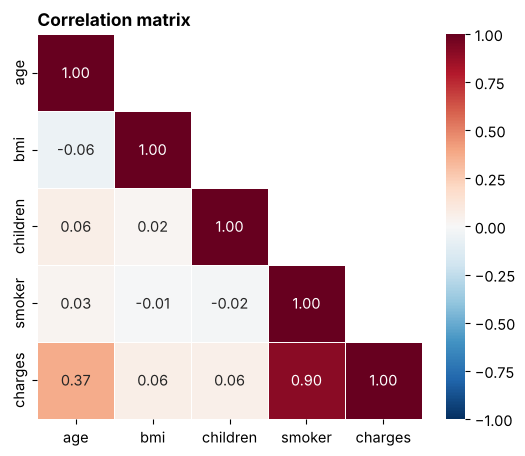

In [7]:
num = ins.assign(smoker=ins["smoker"].eq("yes").astype(int)).select_dtypes("number")
corr = num.corr()
mask = np.triu(np.ones_like(corr, dtype=bool), k=1)
fig, ax = plt.subplots(figsize=(6.2, 5))
sns.heatmap(corr, mask=mask, annot=True, fmt=".2f", cmap="RdBu_r",
            vmin=-1, vmax=1, center=0, square=True, linewidths=0.5, ax=ax)
ax.set_title("Correlation matrix")
ax.grid(False)
plt.show()

<details open><summary><b>What each line does</b></summary>

<table>
<tr><td><code>num = ins.assign(smoker=ins[&quot;smoker&quot;].eq(&quot;yes&quot;).astype(int)).select_dtypes(&quot;number&quot;)</code></td><td>Encode smoker as 0/1, keep numeric columns.</td></tr>
<tr><td><code>corr = num.corr()</code></td><td>Pairwise Pearson correlation matrix.</td></tr>
<tr><td><code>mask = np.triu(np.ones_like(corr, dtype=bool), k=1)</code></td><td>Hide the redundant upper triangle.</td></tr>
<tr><td><code>fig, ax = plt.subplots(figsize=(6.2, 5))</code></td><td>A near-square figure suits a square matrix.</td></tr>
<tr><td><code>sns.heatmap(corr, mask=mask, annot=True, fmt=&quot;.2f&quot;, cmap=&quot;RdBu_r&quot;,</code></td><td>Draw the matrix with numbers to 2 decimals, red = positive, blue = negative...</td></tr>
<tr><td><code>&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;vmin=-1, vmax=1, center=0, square=True, linewidths=0.5, ax=ax)</code></td><td>annot writes the numbers in the cells.</td></tr>
<tr><td><code>ax.set_title(&quot;Correlation matrix&quot;)</code></td><td>Title.</td></tr>
<tr><td><code>ax.grid(False)</code></td><td>No grid lines across the coloured cells (some styles add them).</td></tr>
<tr><td><code>plt.show()</code></td><td>Draw the figure (in a script this opens a window; in Jupyter it appears below the cell).</td></tr>
</table>
</details>

**Pair plot: every pair of variables at once**

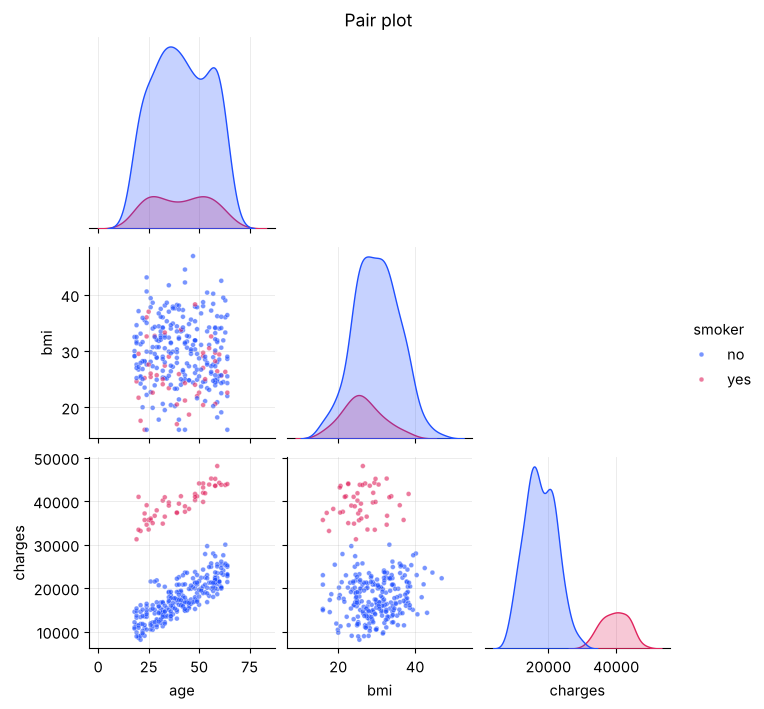

In [8]:
g = sns.pairplot(ins.sample(300, random_state=0), vars=["age", "bmi", "charges"],
                 hue="smoker", corner=True, plot_kws={"s": 12, "alpha": 0.6}, height=2.3)
g.figure.suptitle("Pair plot", y=1.02)
plt.show()

<details open><summary><b>What each line does</b></summary>

<table>
<tr><td><code>g = sns.pairplot(ins.sample(300, random_state=0), vars=[&quot;age&quot;, &quot;bmi&quot;, &quot;charges&quot;],</code></td><td>Pair plot of 300 random rows and three variables...</td></tr>
<tr><td><code>&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;hue=&quot;smoker&quot;, corner=True, plot_kws={&quot;s&quot;: 12, &quot;alpha&quot;: 0.6}, height=2.3)</code></td><td>sample() keeps it fast; corner=True drops the duplicate upper half.</td></tr>
<tr><td><code>g.figure.suptitle(&quot;Pair plot&quot;, y=1.02)</code></td><td>A title above the whole grid (y &gt; 1 places it just above).</td></tr>
<tr><td><code>plt.show()</code></td><td>Draw the figure (in a script this opens a window; in Jupyter it appears below the cell).</td></tr>
</table>
</details>

**Trend lines with uncertainty**

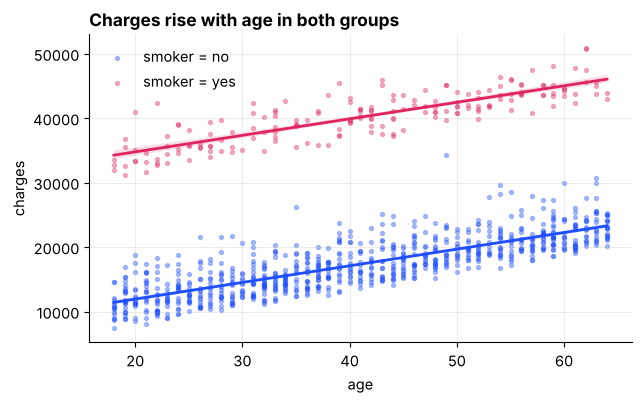

In [9]:
fig, ax = plt.subplots(figsize=(7, 4))
for status, color in [("no", "#1f4fff"), ("yes", "#e0245e")]:
    sub = ins[ins["smoker"] == status]
    sns.regplot(data=sub, x="age", y="charges", scatter_kws={"s": 8, "alpha": 0.35},
                line_kws={"lw": 2}, color=color, label=f"smoker = {status}", ax=ax)
ax.legend()
ax.set_title("Charges rise with age in both groups")
plt.show()

<details open><summary><b>What each line does</b></summary>

<table>
<tr><td><code>fig, ax = plt.subplots(figsize=(7, 4))</code></td><td>One panel.</td></tr>
<tr><td><code>for status, color in [(&quot;no&quot;, &quot;#1f4fff&quot;), (&quot;yes&quot;, &quot;#e0245e&quot;)]:</code></td><td>Loop over <code>[(&quot;no&quot;, &quot;#1f4fff&quot;), (&quot;yes&quot;, &quot;#e0245e&quot;)]</code>, naming each item <code>status, color</code>.</td></tr>
<tr><td><code>&nbsp;&nbsp;&nbsp;&nbsp;sub = ins[ins[&quot;smoker&quot;] == status]</code></td><td>Rows for this smoker group only.</td></tr>
<tr><td><code>&nbsp;&nbsp;&nbsp;&nbsp;sns.regplot(data=sub, x=&quot;age&quot;, y=&quot;charges&quot;, scatter_kws={&quot;s&quot;: 8, &quot;alpha&quot;: 0.35},</code></td><td>Scatter plus fitted line; small, faint points...</td></tr>
<tr><td><code>&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;line_kws={&quot;lw&quot;: 2}, color=color, label=f&quot;smoker = {status}&quot;, ax=ax)</code></td><td>One fitted line per group.</td></tr>
<tr><td><code>ax.legend()</code></td><td>Show a legend built from each plotted series&#x27; <code>label</code>.</td></tr>
<tr><td><code>ax.set_title(&quot;Charges rise with age in both groups&quot;)</code></td><td>A title that states the finding.</td></tr>
<tr><td><code>plt.show()</code></td><td>Draw the figure (in a script this opens a window; in Jupyter it appears below the cell).</td></tr>
</table>
</details>

## 14.5 Plotting directly from pandas · *Beginner*

**DataFrame.plot for quick looks**

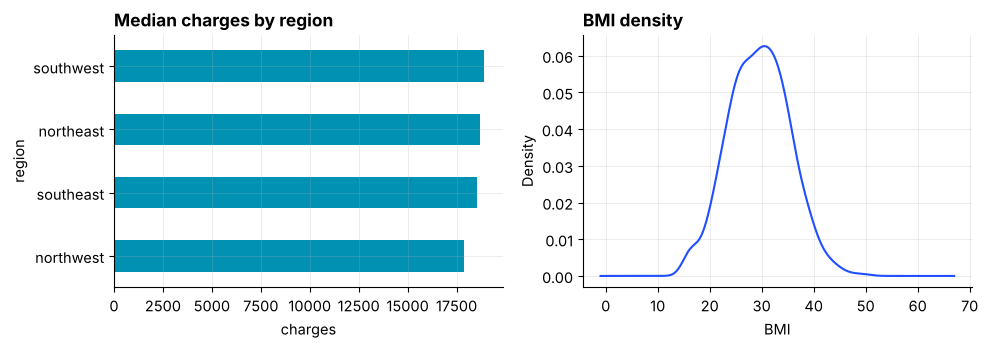

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.6))
ins.groupby("region")["charges"].median().sort_values().plot.barh(ax=axes[0], color="#0091b3")
axes[0].set(title="Median charges by region", xlabel="charges")
ins["bmi"].plot.kde(ax=axes[1])
axes[1].set(title="BMI density", xlabel="BMI")
plt.tight_layout()
plt.show()

<details open><summary><b>What each line does</b></summary>

<table>
<tr><td><code>fig, axes = plt.subplots(1, 2, figsize=(10, 3.6))</code></td><td>Two panels side by side.</td></tr>
<tr><td><code>ins.groupby(&quot;region&quot;)[&quot;charges&quot;].median().sort_values().plot.barh(ax=axes[0], color=&quot;#0091b3&quot;)</code></td><td>Horizontal bars, sorted: easy to read.</td></tr>
<tr><td><code>axes[0].set(title=&quot;Median charges by region&quot;, xlabel=&quot;charges&quot;)</code></td><td>Title and x label.</td></tr>
<tr><td><code>ins[&quot;bmi&quot;].plot.kde(ax=axes[1])</code></td><td>Kernel density estimate: a smooth histogram (needs SciPy).</td></tr>
<tr><td><code>axes[1].set(title=&quot;BMI density&quot;, xlabel=&quot;BMI&quot;)</code></td><td>Title and x label.</td></tr>
<tr><td><code>plt.tight_layout()</code></td><td>Adjust spacing so titles and labels don&#x27;t overlap.</td></tr>
<tr><td><code>plt.show()</code></td><td>Draw the figure (in a script this opens a window; in Jupyter it appears below the cell).</td></tr>
</table>
</details>

## 14.6 Styles, colours and publication-quality export · *Intermediate*

**A reusable publication style**

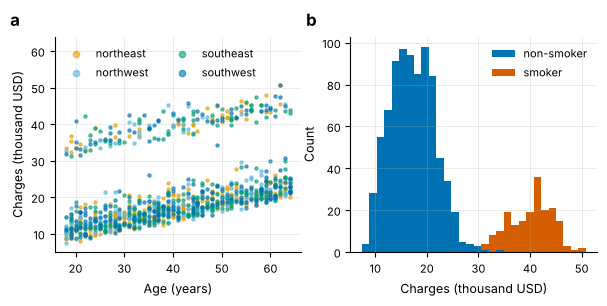

In [11]:
plt.rcParams.update({
    "font.size": 9, "axes.titlesize": 10, "axes.labelsize": 9,
    "xtick.labelsize": 8, "ytick.labelsize": 8, "legend.fontsize": 8,
    "axes.spines.top": False, "axes.spines.right": False,
    "savefig.dpi": 300, "savefig.bbox": "tight",
})
okabe_ito = ["#E69F00", "#56B4E9", "#009E73", "#0072B2", "#D55E00", "#CC79A7"]
fig, axes = plt.subplots(1, 2, figsize=(7.0, 2.8))
for i, (name, grp) in enumerate(ins.groupby("region")):
    axes[0].scatter(grp["age"], grp["charges"] / 1000, s=5, alpha=0.6, color=okabe_ito[i], label=name)
axes[0].set(xlabel="Age (years)", ylabel="Charges (thousand USD)")
axes[0].set_ylim(5, 64)
axes[0].legend(markerscale=2, frameon=False, ncol=2, loc="upper left")
axes[1].hist([ins.loc[ins.smoker == s, "charges"] / 1000 for s in ("no", "yes")],
             bins=30, stacked=True, color=okabe_ito[3:5], label=["non-smoker", "smoker"])
axes[1].set(xlabel="Charges (thousand USD)", ylabel="Count")
axes[1].legend(frameon=False)
for ax, letter in zip(axes, "ab"):
    ax.text(-0.18, 1.05, letter, transform=ax.transAxes, fontsize=12, fontweight="bold")
fig.savefig("figure1.pdf")
fig.savefig("figure1.png", dpi=300)
fig.savefig("figure1.svg")
plt.show()
plt.rcdefaults()

<details open><summary><b>What each line does</b></summary>

<table>
<tr><td><code>plt.rcParams.update({</code></td><td>rcParams = global defaults for every figure in the session.</td></tr>
<tr><td><code>&nbsp;&nbsp;&nbsp;&nbsp;&quot;font.size&quot;: 9, &quot;axes.titlesize&quot;: 10, &quot;axes.labelsize&quot;: 9,</code></td><td>Small fonts that stay legible at print size.</td></tr>
<tr><td><code>&nbsp;&nbsp;&nbsp;&nbsp;&quot;xtick.labelsize&quot;: 8, &quot;ytick.labelsize&quot;: 8, &quot;legend.fontsize&quot;: 8,</code></td><td>Tick and legend text sizes.</td></tr>
<tr><td><code>&nbsp;&nbsp;&nbsp;&nbsp;&quot;axes.spines.top&quot;: False, &quot;axes.spines.right&quot;: False,</code></td><td>Remove the top and right box lines.</td></tr>
<tr><td><code>&nbsp;&nbsp;&nbsp;&nbsp;&quot;savefig.dpi&quot;: 300, &quot;savefig.bbox&quot;: &quot;tight&quot;,</code></td><td>Saved files: 300 dpi, trimmed to the content.</td></tr>
<tr><td><code>})</code></td><td>Close the dictionary and the call or tuple opened above.</td></tr>
<tr><td><code>okabe_ito = [&quot;#E69F00&quot;, &quot;#56B4E9&quot;, &quot;#009E73&quot;, &quot;#0072B2&quot;, &quot;#D55E00&quot;, &quot;#CC79A7&quot;]</code></td><td>The Okabe-Ito colour-blind-safe palette.</td></tr>
<tr><td><code>fig, axes = plt.subplots(1, 2, figsize=(7.0, 2.8))</code></td><td>~7 inches = a typical two-column journal figure width.</td></tr>
<tr><td><code>for i, (name, grp) in enumerate(ins.groupby(&quot;region&quot;)):</code></td><td>Loop over <code>enumerate(ins.groupby(&quot;region&quot;))</code>, naming each item <code>i, (name, grp)</code>.</td></tr>
<tr><td><code>&nbsp;&nbsp;&nbsp;&nbsp;axes[0].scatter(grp[&quot;age&quot;], grp[&quot;charges&quot;] / 1000, s=5, alpha=0.6, color=okabe_ito[i], label=name)</code></td><td>One colour-blind-safe colour per region; charges shown in thousands.</td></tr>
<tr><td><code>axes[0].set(xlabel=&quot;Age (years)&quot;, ylabel=&quot;Charges (thousand USD)&quot;)</code></td><td>Axis labels with units.</td></tr>
<tr><td><code>axes[0].set_ylim(5, 64)</code></td><td>Head-room at the top for the legend.</td></tr>
<tr><td><code>axes[0].legend(markerscale=2, frameon=False, ncol=2, loc=&quot;upper left&quot;)</code></td><td>Bigger legend markers, no frame, two columns, top-left.</td></tr>
<tr><td><code>axes[1].hist([ins.loc[ins.smoker == s, &quot;charges&quot;] / 1000 for s in (&quot;no&quot;, &quot;yes&quot;)],</code></td><td>Two histograms (non-smokers, smokers)...</td></tr>
<tr><td><code>&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;bins=30, stacked=True, color=okabe_ito[3:5], label=[&quot;non-smoker&quot;, &quot;smoker&quot;])</code></td><td>...stacked on top of each other, in two palette colours.</td></tr>
<tr><td><code>axes[1].set(xlabel=&quot;Charges (thousand USD)&quot;, ylabel=&quot;Count&quot;)</code></td><td>Axis labels.</td></tr>
<tr><td><code>axes[1].legend(frameon=False)</code></td><td>Legend without a box.</td></tr>
<tr><td><code>for ax, letter in zip(axes, &quot;ab&quot;):</code></td><td>Loop over <code>zip(axes, &quot;ab&quot;)</code>, naming each item <code>ax, letter</code>.</td></tr>
<tr><td><code>&nbsp;&nbsp;&nbsp;&nbsp;ax.text(-0.18, 1.05, letter, transform=ax.transAxes, fontsize=12, fontweight=&quot;bold&quot;)</code></td><td>Panel letters in axes coordinates (0-1).</td></tr>
<tr><td><code>fig.savefig(&quot;figure1.pdf&quot;)</code></td><td>Vector PDF: infinitely scalable, preferred by journals.</td></tr>
<tr><td><code>fig.savefig(&quot;figure1.png&quot;, dpi=300)</code></td><td>High-resolution raster for slides or the web.</td></tr>
<tr><td><code>fig.savefig(&quot;figure1.svg&quot;)</code></td><td>SVG: editable in Inkscape or Illustrator.</td></tr>
<tr><td><code>plt.show()</code></td><td>Draw the figure (in a script this opens a window; in Jupyter it appears below the cell).</td></tr>
<tr><td><code>plt.rcdefaults()</code></td><td>Restore Matplotlib&#x27;s defaults afterwards.</td></tr>
</table>
</details>

> **🔬 Research practice** · **Figure checklist for papers**
>
> Vector format (PDF/EPS/SVG) for plots, at least 300 dpi for raster images; fonts readable at final print size (≥ 7 pt); axes labelled with units; a colour-blind-safe palette with redundant encoding (markers or line styles); error bars defined in the caption (SD, SEM or 95% CI?); the code that generated each figure kept in your repository.

> **🐞 Bug hunt** · **My saved figure is blank or cut off**
>
> Call `fig.savefig(...)` **before** `plt.show()`: in scripts, `show()` can close the figure. Clipped labels: use `bbox_inches="tight"` or `layout="constrained"`. Tiny text: set `figsize` to the final printed size instead of shrinking a big figure later.

> **✍️ Try it yourself**
>
> 1. Plot the histogram of `charges` and of `np.log(charges)` side by side. Which looks closer to normal?
> 2. Recreate the pair plot with `hue="region"`. Does region matter?
> 3. Make a bar chart of mean charges by number of children with error bars (`sns.barplot` shows a 95% CI by default).
>
> *Worked solutions:* [solutions-parts-1-4.ipynb](../../solutions/solutions-parts-1-4.ipynb), section *Chapter 14*.

---

⬅️ [Chapter 13: Grouping, reshaping, joining and time series](../part-3-pandas/13-pandas-transform.ipynb) · [📚 Contents](../../book/README.md) · [Chapter 15: The Matplotlib chart gallery](15-viz-mpl-gallery.ipynb) ➡️